# Supplementary Figure S2. Backbone suite and ribose pucker assessment


In [1]:
import json
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import Normalize

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 600, "savefig.bbox": "tight",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, GREEN, RED, GREY = "#4C72B0", "#DD8452", "#55A868", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

CUT = 80.0

LW = ["cWW", "tWW", "cWH", "tWH", "cWS", "tWS", "cHH", "tHH", "cHS", "tHS", "cSS", "tSS"]
TOOLS = ["rubric", "fr3d", "rnaview", "barnaba", "rnapolis", "bpnet"]
TOOL_LABELS = ["RUBRIC", "FR3D", "RNAView", "barnaba", "RNApolis", "BPNet"]

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.012):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_rubric.jsonl"), lines=True)

def scored_pairs(lw_only=True) -> pd.DataFrame:
    df = pair_scores()
    df = df[~df["is_ambiguous"].fillna(False) & df["score"].notna()].copy()
    return df[df["lw_class"].isin(LW)].copy() if lw_only else df

def _resolution(m):
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (Å)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (Å)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({"pdb": pdb, "pairs_score": info.get("pairs_score"),
                     "backbone_suiteness": info.get("backbone_suiteness"),
                     "n_pairs": info.get("n_pairs", 0),
                     "n_residues_scored": info.get("n_residues_scored", 0),
                     "method": m.get("Experimental_method"),
                     "resolution": _resolution(m), "clashscore": m.get("clashscore"),
                     "rnasuiteness": m.get("rnasuiteness"),
                     "n_nucleotides": nt.get(pdb),
                     "deposited": m.get("Deposition_Date")})
    return pd.DataFrame(rows)

def runtime() -> pd.DataFrame:
    df = pd.read_csv(data_file("benchmark/dssr_RUBRIC_time_benchmark.csv"))
    df = df[(df["Nucleotides"] > 0) & (df["dssr_avg"] > 0) & (df["rubric_avg"] > 0)].copy()
    df["ratio"] = df["dssr_avg"] / df["rubric_avg"]
    return df

WEIGHTS = _json("reference/scoring_tables/penalty_weights.json")["penalty_weights"]
ISSUES = list(WEIGHTS)
ISSUE_LABELS = {"distance": "H-bond distance", "hbond_angles": "H-bond angles",
                "incorrect_hbond_count": "H-bond count", "stretch": "Stretch",
                "opening": "Opening", "stagger": "Stagger", "propeller": "Propeller",
                "shear": "Shear", "buckle": "Buckle", "clash": "Clash"}

def hist_grid(fig, spec, df, params, xlabel, cols=3):
    rows = int(np.ceil(len(params) / cols))
    sub = spec.subgridspec(rows, cols, wspace=0.42, hspace=0.62)
    axes = []
    for i, p in enumerate(params):
        ax = fig.add_subplot(sub[i // cols, i % cols])
        vals = pd.to_numeric(df[p], errors="coerce").dropna()
        if len(vals) > 20000:
            vals = vals.sample(20000, random_state=1)
        ax.hist(vals, bins=40, color=BLUE, alpha=0.8)
        ax.set_xlabel(p.replace("_", " "), fontsize=7.5)
        ax.tick_params(labelsize=6.5)
        if i % cols == 0:
            ax.set_ylabel("Count", fontsize=7.5)
        finish(ax)
        axes.append(ax)
    return axes

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


## Panel setup
Structure and residue tables


In [2]:
STRUCT = structure_scores()
TOR = pd.read_csv(data_file("reference/high_quality_features/torsions.csv"))
TOR["is_outlier"] = TOR["is_outlier"].fillna(False).astype(bool)
print(f"{len(STRUCT):,} structures | {len(TOR):,} scored residues")

Q = pd.read_csv(data_file("reference/quality_axes/bang_vs_quality.csv"))

def quality_axis(ax, axis_name, xlabel, color=BLUE, logx=False, rotate=0):
    d = Q[Q.axis == axis_name]
    ax.errorbar(d.x, d.rate, yerr=d.sd, fmt="o-", color=color, lw=1.6, ms=5.5,
                capsize=3.5, ecolor=color, elinewidth=1.0)
    if logx:
        ax.set_xscale("log")
    ax.set_xticks(d.x)
    ax.set_xticklabels(d.bin, fontsize=7, rotation=rotate,
                       ha="right" if rotate else "center")
    ax.minorticks_off()
    ax.text(0.03, 0.96, f"n = {int(d.n_molecules.sum()):,} molecules",
            transform=ax.transAxes, ha="left", va="top", fontsize=7.5, color="0.35")
    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylim(-10, 60)
    ax.set_ylabel("Unassigned suites (%)", fontsize=11)
    finish(ax)

RES = TOR[TOR.res_id.str.split("-").str[1].isin(["A", "C", "G", "U"])]
RES = RES[RES.lw_class.isin(LW)].copy()

CANON_BP = {"A-U", "U-A", "G-C", "C-G"}
RES["row_class"] = np.where(
    RES.lw_class.ne("cWW"), RES.lw_class,
    np.where(RES.bp_type.isin(CANON_BP), "cWW", "cWW*"))
LWROWS = ["cWW", "cWW*"] + [c for c in LW if c != "cWW"]

LETTER_3, LETTER_2 = set("acdefghijklmn"), set("bopqrstuvwxyz[")

def pucker_from_name(conf):
    if not isinstance(conf, str) or len(conf) < 2:
        return "neither"
    ch = conf[1].lower()
    return "C3′-endo" if ch in LETTER_3 else "C2′-endo" if ch in LETTER_2 else "neither"

def conformer_pucker(df):
    med = df[~df.is_outlier].groupby("conformer").delta.median()
    return {c: ("C3′-endo" if 60 <= v <= 105 else
                "C2′-endo" if 125 <= v <= 165 else "neither") for c, v in med.items()}

def conformer_matrix(df, rows, cols=None):
    d = df.assign(cell=np.where(df.is_outlier, "!!", df.conformer))
    tab = pd.crosstab(d.row_class, d.cell).reindex(rows).dropna(how="all")
    share = 100 * tab.div(tab.sum(axis=1), axis=0)
    bang = share["!!"] if "!!" in share else pd.Series(0.0, index=share.index)
    if cols is None:
        conf = [c for c in share.columns if c != "!!"]
        cols = list(tab[conf].sum(axis=0).sort_values(ascending=False).head(12).index)
        cols += [c for c in conf if share[c].max() >= 3 and c not in cols]
        cols = sorted(cols, key=lambda c: -tab[c].sum())
        puck = conformer_pucker(df)
        cols = ([c for c in cols if puck.get(c) == "C3′-endo"]
                + [c for c in cols if puck.get(c) == "C2′-endo"]
                + [c for c in cols if puck.get(c) not in ("C3′-endo", "C2′-endo")])
    use = share.reindex(columns=cols).fillna(0.0)
    use["others"] = 100 - use.sum(axis=1) - bang
    named = [c for c in use.columns if c != "others"]
    rare = use[named] < 1
    use["others"] = use["others"] + use[named].where(rare).sum(axis=1)
    use[named] = use[named].mask(rare, 0.0)
    use["!!"] = bang
    return use, cols

def whole_percent(row):
    v = row.to_numpy(float)
    base = np.floor(v).astype(int)
    deficit = int(round(100 - base.sum()))
    if deficit > 0:
        frac = v - base
        frac[v == 0] = -1.0
        for j in np.argsort(-frac)[:deficit]:
            base[j] += 1
    return pd.Series(base, index=row.index)

def pucker_bracket(ax, spans, y=1.03, tick=0.024):
    tr = ax.get_xaxis_transform()
    for label, x0, x1, colour in spans:
        ax.plot([x0 - 0.42, x0 - 0.42, x1 + 0.42, x1 + 0.42],
                [y - tick, y, y, y - tick], transform=tr, color=colour, lw=1.1,
                clip_on=False, solid_capstyle="butt")
        ax.text((x0 + x1) / 2, y + 0.012, label, transform=tr, ha="center",
                va="bottom", fontsize=9, color=colour, clip_on=False)


2,697 structures | 739,658 scored residues


## Panel A
RUBRIC-calculated backbone suiteness versus PDB RNA suiteness


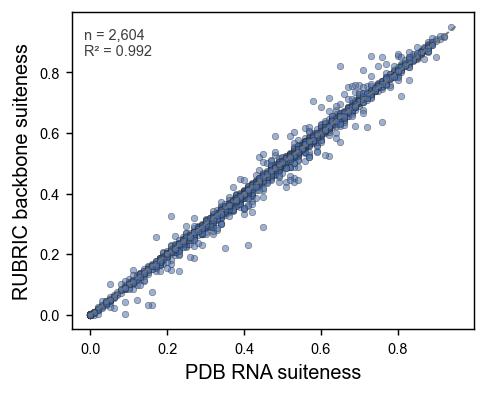

In [3]:
def draw_a(ax):
    d = STRUCT.dropna(subset=["rnasuiteness", "backbone_suiteness"])
    ax.scatter(d.rnasuiteness, d.backbone_suiteness, s=13, facecolor=BLUE,
               edgecolor=POINT_EDGE, linewidths=0.35, alpha=0.55)
    lo = min(d.rnasuiteness.min(), d.backbone_suiteness.min())
    hi = max(d.rnasuiteness.max(), d.backbone_suiteness.max())
    ax.plot([lo, hi], [lo, hi], "--", color="0.45", lw=1.0)
    r = np.corrcoef(d.rnasuiteness, d.backbone_suiteness)[0, 1]
    ax.text(0.03, 0.95, f"n = {len(d):,}\nR\u00b2 = {r**2:.3f}", transform=ax.transAxes,
            ha="left", va="top", fontsize=8, color="0.25")
    ax.set_xlabel("PDB RNA suiteness", fontsize=11)
    ax.set_ylabel("RUBRIC backbone suiteness", fontsize=11)
    finish(ax)


fig, ax = plt.subplots(figsize=(3.8, 3.1))
draw_a(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS2_A_suiteness_vs_pdb.png")
plt.show()


## Panel B-C
Unassigned backbone suites versus resolution and clashscore


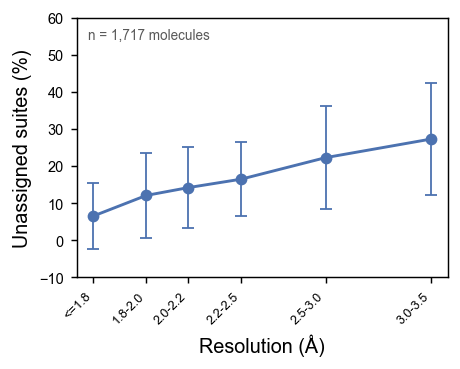

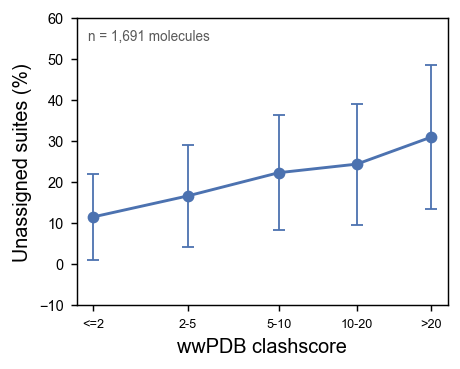

In [4]:
def draw_b(ax):
    quality_axis(ax, "resolution", "Resolution (\u00c5)", rotate=45)

def draw_c(ax):
    quality_axis(ax, "clashscore", "wwPDB clashscore", logx=True)

for fn, name in ((draw_b, "B_unassigned_vs_resolution"), (draw_c, "C_unassigned_vs_clashscore")):
    fig, ax = plt.subplots(figsize=(3.6, 2.9))
    fn(ax)
    fig.tight_layout()
    save(fig, f"figures/supplemental/figS2_{name}.png")
    plt.show()


## Panel D
Ribose pucker from δ and Pperp in the curated reference set


855,264 residues from 1,290 structures
  C3′-endo       726,448  84.938%
  C2′-endo       126,521  14.793%
  flagged            436   0.051%
  unclassified     1,859   0.217%
  outside the plotted delta range: 40


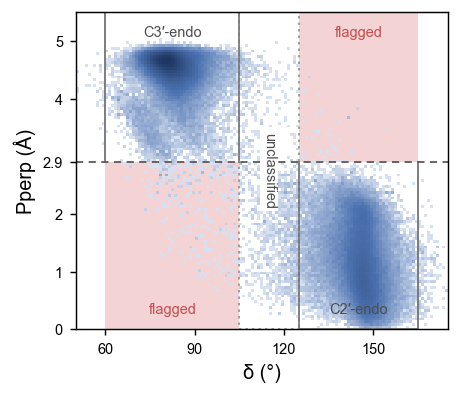

In [5]:
PK = pd.read_csv(data_file("reference/high_quality_features/pucker.csv"))
PK["delta"] = PK["delta"] % 360
C3_RANGE, C2_RANGE, PPERP_CUT = (60, 105), (125, 165), 2.9   # Suitename delta ranges; Pperp cutoff
DX, DY = (50, 175), (0, 5.5)


def pucker_zones(d=PK.delta, p=PK.pperp):
    c3, c2 = d.between(*C3_RANGE), d.between(*C2_RANGE)
    return {"C3′-endo": c3 & (p >= PPERP_CUT), "C2′-endo": c2 & (p < PPERP_CUT),
            "flagged": (c3 & (p < PPERP_CUT)) | (c2 & (p >= PPERP_CUT)),
            "unclassified": ~(c3 | c2)}


print(f"{len(PK):,} residues from {PK.pdb_id.nunique():,} structures")
for k, m in pucker_zones().items():
    print(f"  {k:13s} {int(m.sum()):8,d}  {100 * m.mean():6.3f}%")
print(f"  outside the plotted delta range: {int((~PK.delta.between(*DX)).sum()):,}")


def draw_d(ax):
    from matplotlib.colors import LinearSegmentedColormap, LogNorm
    from matplotlib.patches import Rectangle
    # agreement regions: outlined on three sides, the dashed cutoff marks the fourth
    for (x0, x1), (y0, y1) in ((C3_RANGE, (PPERP_CUT, DY[1])), (C2_RANGE, (DY[0], PPERP_CUT))):
        ys = (y1, y0) if y0 == PPERP_CUT else (y0, y1)
        ax.plot([x0, x0, x1, x1], [ys[1], ys[0], ys[0], ys[1]], color="0.45", lw=1.0,
                zorder=2, solid_joinstyle="miter")
    for (x0, x1), (y0, y1) in ((C3_RANGE, (DY[0], PPERP_CUT)), (C2_RANGE, (PPERP_CUT, DY[1]))):
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, facecolor="#f4d3d4",
                               edgecolor="none", zorder=0))
    ax.add_patch(Rectangle((C3_RANGE[1], DY[0]), C2_RANGE[0] - C3_RANGE[1], DY[1] - DY[0],
                           facecolor="none", edgecolor="0.55", lw=0.9, ls=(0, (1.5, 2.5)), zorder=2))
    cmap = LinearSegmentedColormap.from_list("pk", ["#d6e0f0", BLUE, "#1d3560"])
    ax.hist2d(PK.delta, PK.pperp, bins=[np.linspace(*DX, 126), np.linspace(*DY, 111)],
              cmap=cmap, norm=LogNorm(vmin=1), cmin=1, zorder=1, rasterized=True)
    ax.axhline(PPERP_CUT, color="0.35", lw=1.0, ls=(0, (4, 3)), zorder=2)
    mid = lambda r: sum(r) / 2
    for x, y, lab, col in ((mid(C3_RANGE), 5.15, "C3\u2032-endo", "0.3"),
                           (mid(C2_RANGE), 0.35, "C2\u2032-endo", "0.3"),
                           (mid(C3_RANGE), 0.35, "flagged", RED),
                           (mid(C2_RANGE), 5.15, "flagged", RED)):
        ax.text(x, y, lab, ha="center", va="center", fontsize=8, color=col, zorder=3)
    ax.text(mid((C3_RANGE[1], C2_RANGE[0])), mid(DY), "unclassified", ha="center", va="center",
            rotation=270, fontsize=8, color="0.3", zorder=3,
            bbox=dict(boxstyle="square,pad=0.15", facecolor="white", edgecolor="none"))
    ax.set_xlim(*DX); ax.set_ylim(*DY)
    ax.set_xticks([60, 90, 120, 150])
    ax.set_yticks([0, 1, 2, PPERP_CUT, 4, 5]); ax.set_yticklabels(["0", "1", "2", "2.9", "4", "5"])
    ax.set_xlabel("\u03b4 (\u00b0)", fontsize=11)
    ax.set_ylabel("Pperp (\u00c5)", fontsize=11)
    finish(ax)


fig, ax = plt.subplots(figsize=(3.6, 3.1))
draw_d(ax)
fig.tight_layout()
save(fig, "figures/supplemental/figS2_D_delta_vs_pperp.png")
plt.show()


## Combined figure


text scaled x1.48: 7 pt prints at 7.1 pt at page width


axis titles print at 8.5 pt and panel letters at 12.0 pt (9.86 in saved, shown at 6.73 in)


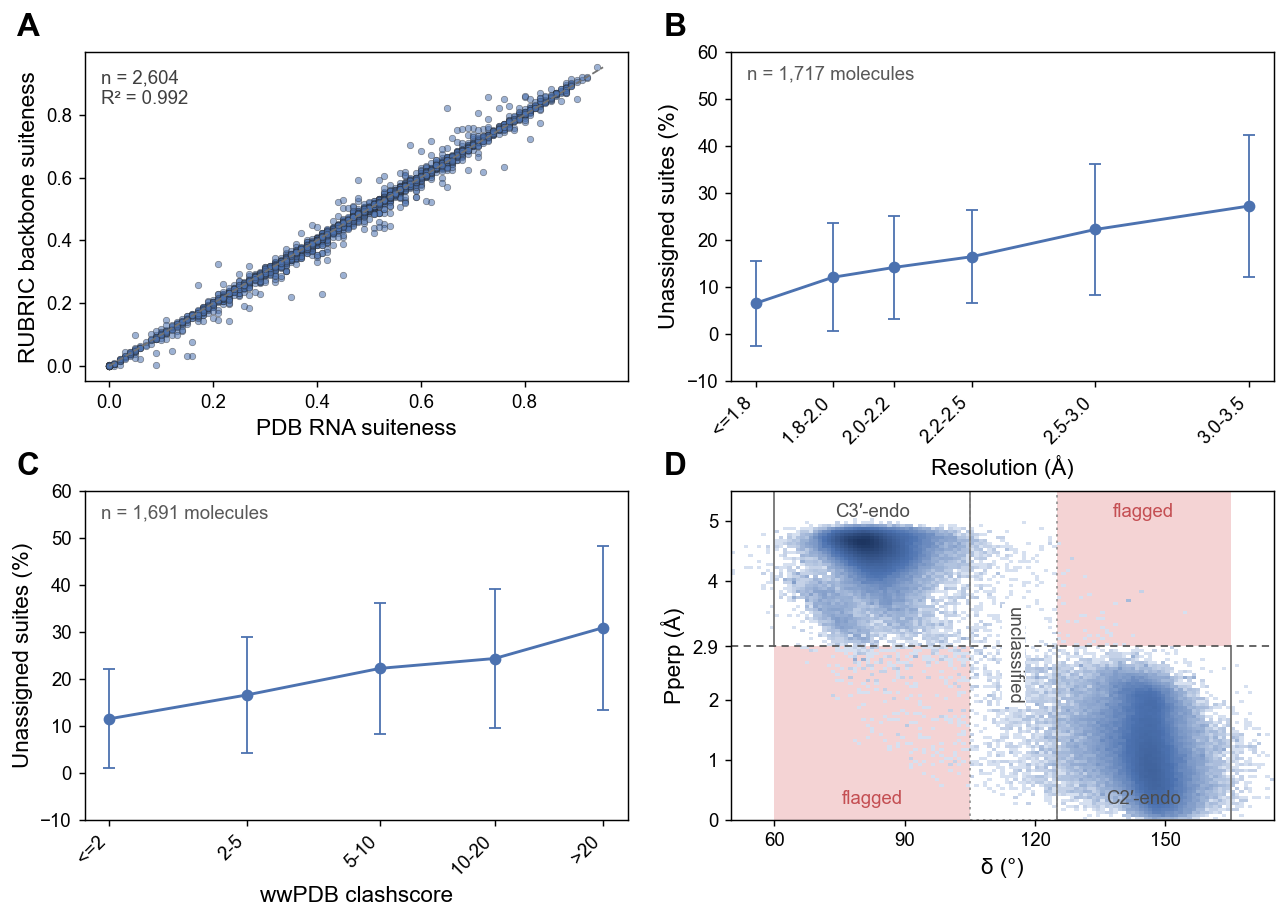

In [6]:
fig = plt.figure(figsize=(10.0, 6.67))
top = fig.add_gridspec(2, 2, hspace=0.335, wspace=0.19,
                       left=0.07, right=0.985, top=0.955, bottom=0.07)
ax_a, ax_b = (fig.add_subplot(top[0, k]) for k in range(2))
ax_c, ax_d = (fig.add_subplot(top[1, k]) for k in range(2))
draw_a(ax_a); draw_b(ax_b); draw_c(ax_c); draw_d(ax_d)
plt.setp(ax_c.get_xticklabels(), rotation=45, ha="right")   # five bins share a narrow panel
for ax, s in ((ax_a, "A"), (ax_b, "B"), (ax_c, "C"), (ax_d, "D")):
    letter(fig, ax, s, dx=-0.052)
import matplotlib.text as mtext
for _t in fig.findobj(mtext.Text):
    if _t in fig.texts and _t.get_fontweight() in ("bold", 700) and len(_t.get_text().strip()) <= 2:
        _t.set_fontsize(12)
    else:
        _t.set_fontsize(7)
enlarge_axis_labels(fig)
for _ax in fig.axes:
    _ax.xaxis.label.set_fontsize(7)
    _ax.yaxis.label.set_fontsize(7)
import matplotlib.text as _mtext
def _print_scale(fig, page_in=6.73, pad=0.08):
    fig.canvas.draw()
    bb = fig.get_tightbbox(fig.canvas.get_renderer())
    return max(1.0, (bb.width + 2 * pad) / page_in)
fig.canvas.draw()
_texts = [t for t in fig.findobj(_mtext.Text) if t.get_text().strip()]
_base = {t: t.get_fontsize() for t in _texts}
_s = 1.0
for _ in range(6):
    _need = _print_scale(fig)
    if _s >= _need - 1e-3:
        break
    _s = _need * 1.01
    for _t in _texts:
        _t.set_fontsize(_base[_t] * _s)
print(f"text scaled x{_s:.2f}: 7 pt prints at {7 * _s / _print_scale(fig):.1f} pt "
      f"at page width")
def _set_print_sizes(fig, axis_pt=8.5, letter_pt=12.0, page_in=6.73, pad=0.08):
    letters = [t for t in fig.texts if t.get_text().strip().isalpha()
               and t.get_text().strip().isupper() and len(t.get_text().strip()) <= 2
               and t.get_fontweight() in ("bold", 700)]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        for ax in fig.axes:
            for lab in (ax.xaxis.label, ax.yaxis.label):
                if lab.get_text().strip():
                    lab.set_fontsize(axis_pt * shrink)
        for t in letters:
            t.set_fontsize(letter_pt * shrink)
    print(f"axis titles print at {axis_pt} pt and panel letters at {letter_pt} pt "
          f"({bb.width + 2 * pad:.2f} in saved, shown at {min(page_in, bb.width + 2 * pad):.2f} in)")


_set_print_sizes(fig)

save(fig, "figures/supplemental/figS2.png")
plt.show()
